In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from statsmodels.tsa.deterministic import DeterministicProcess
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split

waktu = pd.date_range("2010-01-01", "2019-12-31", freq="M")
tren_asli = np.linspace(100, 500, len(waktu))
musiman_asli = np.sin(np.arange(len(waktu)) * (2 * np.pi / 12)) * 50
penjualan = tren_asli + musiman_asli + np.random.normal(0, 10, len(waktu))

df = pd.DataFrame({'Sales': penjualan}, index=waktu)

train_size = int(len(df) * 0.8)
df_train, df_test = df.iloc[:train_size].copy(), df.iloc[train_size:].copy()

In [20]:
dp = DeterministicProcess(index=df.index, order=1, constant=True)
X_trend_full = dp.in_sample()

X_train_1 = X_trend_full.iloc[:train_size]
X_test_1 = X_trend_full.iloc[train_size:]

# Target
y_train = df_train['Sales']
y_test = df_test['Sales']

# Fitur untuk XGBoost (Model 2): Bulan
X_train_2 = pd.DataFrame({'Month': df_train.index.month}, index=df_train.index)
X_test_2 = pd.DataFrame({'Month': df_test.index.month}, index=df_test.index)

print(X_train_1.head())
print(X_test_1.head())
print(X_train_2.head())
print(X_test_2.head())

            const  trend
2010-01-31    1.0    1.0
2010-02-28    1.0    2.0
2010-03-31    1.0    3.0
2010-04-30    1.0    4.0
2010-05-31    1.0    5.0
            const  trend
2018-01-31    1.0   97.0
2018-02-28    1.0   98.0
2018-03-31    1.0   99.0
2018-04-30    1.0  100.0
2018-05-31    1.0  101.0
            Month
2010-01-31      1
2010-02-28      2
2010-03-31      3
2010-04-30      4
2010-05-31      5
            Month
2018-01-31      1
2018-02-28      2
2018-03-31      3
2018-04-30      4
2018-05-31      5


In [19]:
model_1 = LinearRegression(fit_intercept=False)
model_1.fit(X_train_1, y_train)

# Prediksi tren pada data latih dan data uji
y_pred_1_train = pd.Series(model_1.predict(X_train_1), index=y_train.index)
y_pred_1_test = pd.Series(model_1.predict(X_test_1), index=y_test.index)

y_resid_train = y_train - y_pred_1_train

model_2 = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=0)
model_2.fit(X_train_2, y_resid_train)

# Prediksi residual pada data latih dan data uji
y_pred_2_train = pd.Series(model_2.predict(X_train_2), index=y_train.index)
y_pred_2_test = pd.Series(model_2.predict(X_test_2), index=y_test.index)

# Menjumlahkan prediksi tren dan prediksi residual
y_pred_final_train = y_pred_1_train + y_pred_2_train
y_pred_final_test = y_pred_1_test + y_pred_2_test

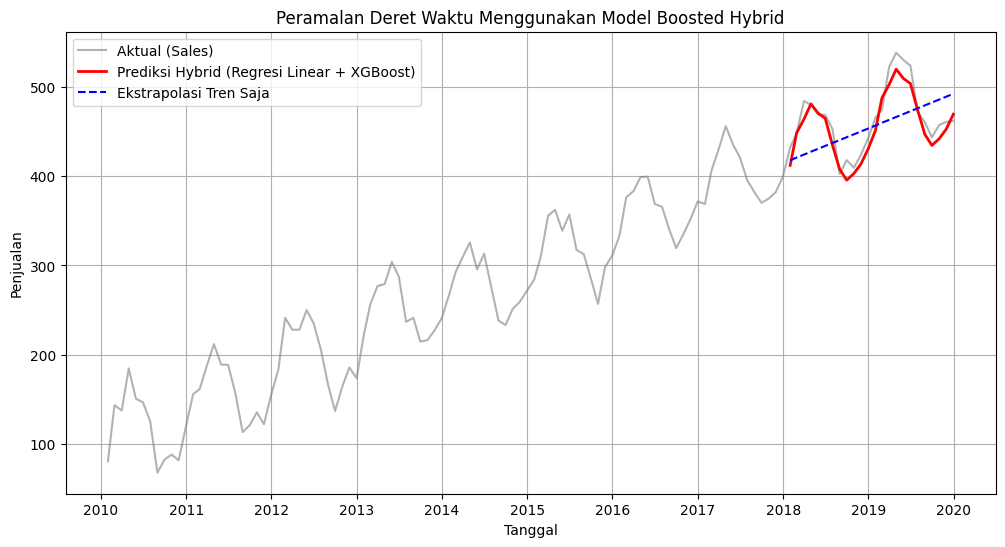

In [21]:
# Visualisasi hasil prediksi
plt.figure(figsize=(12, 6))

# Plot Aktual
plt.plot(df.index, df['Sales'], label='Aktual (Sales)', color='gray', alpha=0.6)

# Plot Prediksi Final pada Data Uji (Test Data)
plt.plot(y_pred_final_test.index, y_pred_final_test, label='Prediksi Hybrid (Regresi Linear + XGBoost)', color='red', linewidth=2)

# Plot Tren Saja (Sebagai Perbandingan)
plt.plot(y_pred_1_test.index, y_pred_1_test, label='Ekstrapolasi Tren Saja', color='blue', linestyle='--')

plt.title("Peramalan Deret Waktu Menggunakan Model Boosted Hybrid")
plt.xlabel("Tanggal")
plt.ylabel("Penjualan")
plt.legend()
plt.grid(True)
plt.show()

--- Preview Fitur ---
X_train_1 (Linear Regression):
             const  trend
Date                    
2022-01-03    1.0    1.0
2022-01-04    1.0    2.0
2022-01-05    1.0    3.0
2022-01-06    1.0    4.0
2022-01-07    1.0    5.0 

X_train_2 (XGBoost):
             Month
Date             
2022-01-03      1
2022-01-04      1
2022-01-05      1
2022-01-06      1
2022-01-07      1 

--- Evaluasi Model ---
Test RMSE: 31191.60
Test MAE:  24888.50
Test MAPE: 96.63%



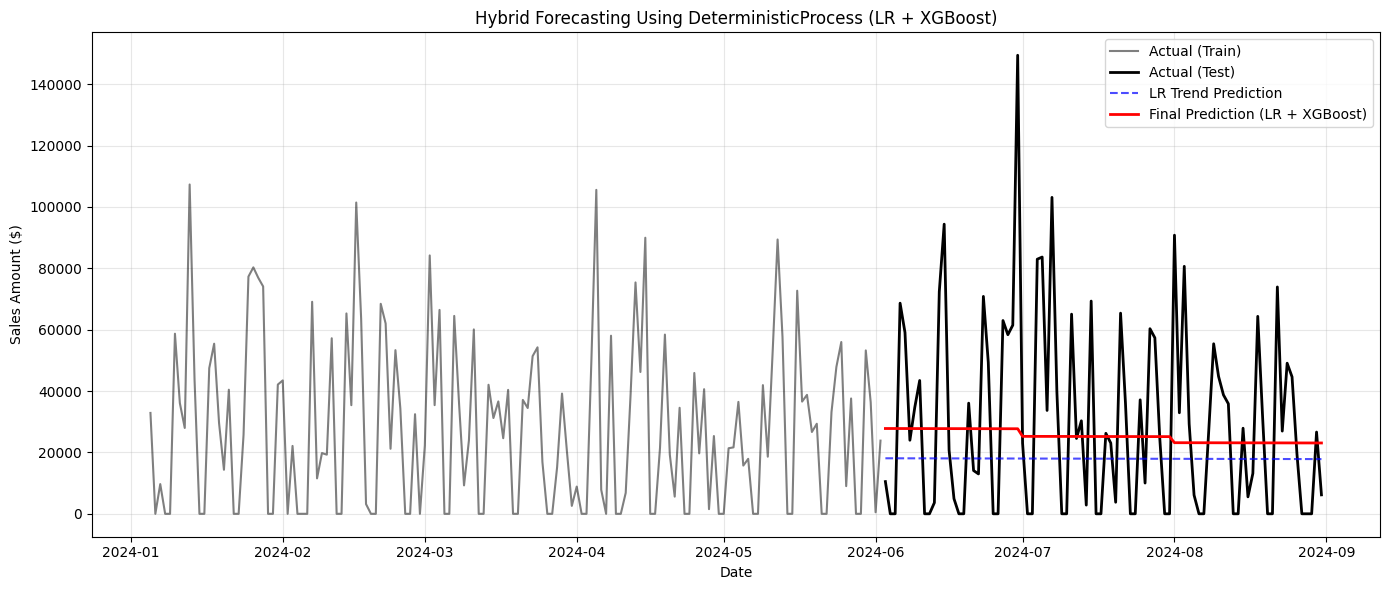

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
from statsmodels.tsa.deterministic import DeterministicProcess
import warnings
warnings.filterwarnings('ignore')

# ==========================================
# 1. Cleaning Data
# ==========================================
df = pd.read_csv('chocolate_sales.csv')

# Membersihkan simbol mata uang dan mengubah ke tipe numerik
if df['Amount'].dtype == 'object':
    df['Amount'] = df['Amount'].replace('[\$,]', '', regex=True).astype(float)

# Parsing tanggal
df['Date'] = pd.to_datetime(df['Date'], format='%d/%m/%Y', errors='coerce')

# Agregasi data harian & memastikan kelengkapan indeks tanggal
daily_sales = df.groupby('Date').agg({'Amount': 'sum'}).reset_index()
daily_sales = daily_sales.sort_values('Date').set_index('Date')
daily_sales = daily_sales.resample('D').sum() 

# Memastikan index memiliki frekuensi 'D' agar kompatibel optimal dengan DeterministicProcess
daily_sales.index.freq = 'D'

# Mengganti nama kolom target agar sesuai dengan konteks Anda
df_ts = daily_sales[['Amount']].rename(columns={'Amount': 'Sales'})

# Split Data (misal 90 hari terakhir untuk Testing)
test_size = 90
train_size = len(df_ts) - test_size

df_train = df_ts.iloc[:train_size]
df_test = df_ts.iloc[train_size:]

# ==========================================
# 2. Feature Engineering (Deterministic Process)
# ==========================================
# Menggunakan library statsmodels (Bisa juga ditambahkan parameter `seasonal=True, period=7` 
# jika Anda ingin library ini otomatis membuat fitur dummy musiman mingguan)
dp = DeterministicProcess(index=df_ts.index, order=1, constant=True)
X_trend_full = dp.in_sample()

# Fitur untuk Linear Regression (Model 1)
X_train_1 = X_trend_full.iloc[:train_size]
X_test_1 = X_trend_full.iloc[train_size:]

# Target
y_train = df_train['Sales']
y_test = df_test['Sales']

# Fitur untuk XGBoost (Model 2): Bulan (serta opsional Hari)
X_train_2 = pd.DataFrame({'Month': df_train.index.month}, index=df_train.index)
X_test_2 = pd.DataFrame({'Month': df_test.index.month}, index=df_test.index)

print("--- Preview Fitur ---")
print("X_train_1 (Linear Regression):\n", X_train_1.head(), "\n")
print("X_train_2 (XGBoost):\n", X_train_2.head(), "\n")

# ==========================================
# 3. Model Linear Regression & XGBoost
# ==========================================

# --- Tahap 1: Melatih Model Linear Regression ---
lr = LinearRegression()
lr.fit(X_train_1, y_train)

# --- Tahap 2: Menghasilkan Data Residu ---
# Prediksi data latih untuk mendapatkan selisih/residu aktual
y_pred_train_lr = lr.predict(X_train_1)
residuals_train = y_train - y_pred_train_lr

# --- Tahap 3: Melatih XGBoost menggunakan Residu ---
xgb = XGBRegressor(n_estimators=100, learning_rate=0.05, random_state=42)
xgb.fit(X_train_2, residuals_train)

# --- Tahap 4: Prediksi Hybrid pada Test Set ---
y_pred_test_lr = lr.predict(X_test_1)               # Prediksi Baseline (Trend)
y_pred_test_xgb = xgb.predict(X_test_2)             # Prediksi Residual (Pattern bulanan)

# Penggabungan Prediksi & clipping di angka 0
final_predictions = y_pred_test_lr + y_pred_test_xgb
final_predictions = np.clip(final_predictions, a_min=0, a_max=None)

# ==========================================
# 4. Evaluasi Model
# ==========================================
rmse = np.sqrt(mean_squared_error(y_test, final_predictions))
mae = mean_absolute_error(y_test, final_predictions)
mape = mean_absolute_percentage_error(y_test[y_test > 0], final_predictions[y_test > 0]) * 100

print("--- Evaluasi Model ---")
print(f"Test RMSE: {rmse:.2f}")
print(f"Test MAE:  {mae:.2f}")
print(f"Test MAPE: {mape:.2f}%\n")

# Menyimpan kembali prediksi ke dalam DataFrame untuk Plotting
df_test_plot = df_test.copy()
df_test_plot['LR_Pred'] = y_pred_test_lr
df_test_plot['Final_Pred'] = final_predictions

df_train_plot = df_train.copy()
df_train_plot['Final_Pred'] = np.clip(y_pred_train_lr + xgb.predict(X_train_2), a_min=0, a_max=None)

# Visualisasi
plt.figure(figsize=(14, 6))
# Plot data latih yang cukup dekat (150 hari terakhir)
plt.plot(df_train_plot.index[-150:], df_train_plot['Sales'].iloc[-150:], label='Actual (Train)', color='black', alpha=0.5)
# Plot target aktual test
plt.plot(df_test_plot.index, df_test_plot['Sales'], label='Actual (Test)', color='black', linewidth=2)
# Plot prediksi LR
plt.plot(df_test_plot.index, df_test_plot['LR_Pred'], label='LR Trend Prediction', color='blue', linestyle='--', alpha=0.7)
# Plot prediksi akhir (Hybrid)
plt.plot(df_test_plot.index, df_test_plot['Final_Pred'], label='Final Prediction (LR + XGBoost)', color='red', linewidth=2)

plt.title('Hybrid Forecasting Using DeterministicProcess (LR + XGBoost)')
plt.xlabel('Date')
plt.ylabel('Sales Amount ($)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()